In [1]:
import pandas as pd
import numpy as np

In [2]:
#Problem 1
# Load the dataset
df = pd.read_csv('mallcustomers.csv')

#look at data
print(df.head())

# Check data types
print(df.dtypes)


   CustomerID  Gender  Age      Income  SpendingScore
0           1    Male   19  15,000 USD             39
1           2    Male   21  15,000 USD             81
2           3  Female   20  16,000 USD              6
3           4  Female   23  16,000 USD             77
4           5  Female   31  17,000 USD             40
CustomerID        int64
Gender           object
Age               int64
Income           object
SpendingScore     int64
dtype: object


In [3]:
# Remove commas and "USD" 
df['Income'] = pd.to_numeric(
    df['Income'].str.replace(',', '').str.replace('USD', '').str.strip()
)

# check data types
print(df.dtypes)

# check the cleaned dataset
print(df.head())

CustomerID        int64
Gender           object
Age               int64
Income            int64
SpendingScore     int64
dtype: object
   CustomerID  Gender  Age  Income  SpendingScore
0           1    Male   19   15000             39
1           2    Male   21   15000             81
2           3  Female   20   16000              6
3           4  Female   23   16000             77
4           5  Female   31   17000             40


In [4]:
#Problem 2

# remove CustomerID 
df = df.drop(columns=['CustomerID'])

#check it
print(df.head())

   Gender  Age  Income  SpendingScore
0    Male   19   15000             39
1    Male   21   15000             81
2  Female   20   16000              6
3  Female   23   16000             77
4  Female   31   17000             40


In [5]:
from sklearn.preprocessing import StandardScaler

# Summary stats
print(df[['Income', 'SpendingScore']].describe())

              Income  SpendingScore
count     200.000000     200.000000
mean    60560.000000      50.200000
std     26264.721165      25.823522
min     15000.000000       1.000000
25%     41500.000000      34.750000
50%     61500.000000      50.000000
75%     78000.000000      73.000000
max    137000.000000      99.000000


In [6]:
# Apply z-score normalization
scaler = StandardScaler()

df[['Income', 'SpendingScore']] = scaler.fit_transform(
    df[['Income', 'SpendingScore']]
)

In [7]:
# Check if normalized
print(df[['Income', 'SpendingScore']].describe())

             Income  SpendingScore
count  2.000000e+02   2.000000e+02
mean  -1.421085e-16  -1.465494e-16
std    1.002509e+00   1.002509e+00
min   -1.738999e+00  -1.910021e+00
25%   -7.275093e-01  -5.997931e-01
50%    3.587926e-02  -7.764312e-03
75%    6.656748e-01   8.851316e-01
max    2.917671e+00   1.894492e+00


c:\Users\JordanRaeHillman\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\JordanRaeHillman\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\JordanRaeHillman\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\JordanRaeHillman\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMe

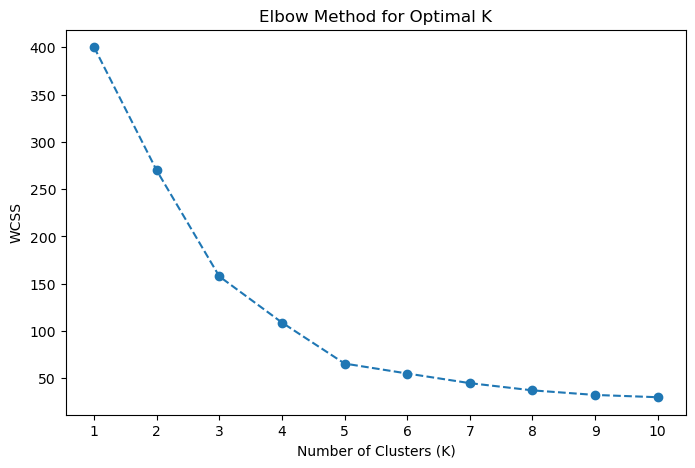

In [8]:
#Problem 4
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

X = df[['Income', 'SpendingScore']]

# Compute WCSS
wcss = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

# Plot Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(K_range, wcss, marker='o', linestyle='--')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method for Optimal K')
plt.xticks(K_range)
plt.show()

In [9]:
# Set optimal K based on Elbow Method
k = 5

# Apply K-means clustering
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)

# Assign each customer to a cluster
df['Cluster'] = kmeans.fit_predict(X)

# Preview results
print(df.head())

# Count customers in each cluster
print(df['Cluster'].value_counts().sort_index())

   Gender  Age    Income  SpendingScore  Cluster
0    Male   19 -1.738999      -0.434801        4
1    Male   21 -1.738999       1.195704        2
2  Female   20 -1.700830      -1.715913        4
3  Female   23 -1.700830       1.040418        2
4  Female   31 -1.662660      -0.395980        4
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


c:\Users\JordanRaeHillman\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


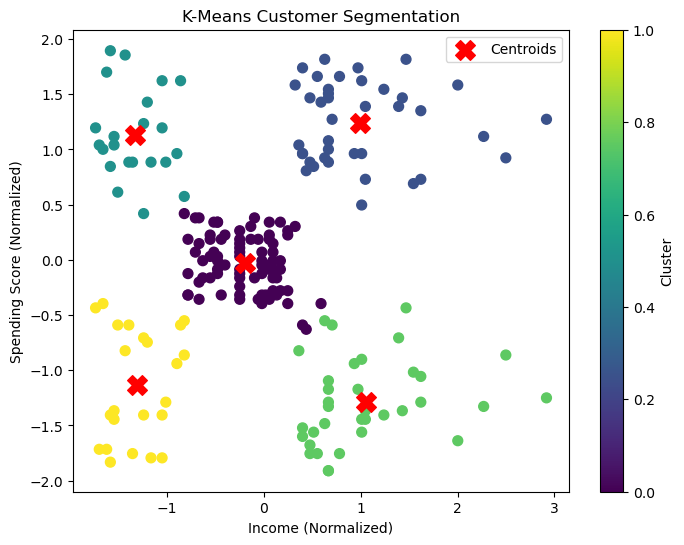

In [10]:
# Visualize customer segments
plt.figure(figsize=(8, 6))

plt.scatter(
    df['Income'],
    df['SpendingScore'],
    c=df['Cluster'],
    cmap='viridis',
    s=50
)

# Plot  centers
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    c='red',
    marker='X',
    s=200,
    label='Centroids'
)

plt.xlabel('Income (Normalized)')
plt.ylabel('Spending Score (Normalized)')
plt.title('K-Means Customer Segmentation')
plt.legend()
plt.colorbar(label='Cluster')
plt.show()

In [11]:
# Calculate mean Income and SpendingScore for each cluster
cluster_summary = df.groupby('Cluster')[['Income', 'SpendingScore']].mean()

print(cluster_summary)


           Income  SpendingScore
Cluster                         
0       -0.200913      -0.026456
1        0.991583       1.239503
2       -1.329545       1.132178
3        1.055003      -1.284439
4       -1.307519      -1.136965


In [12]:
# Assign descriptive names to each cluster
cluster_names = {
    0: 'Average Customers',
    1: 'Higher Income High Spend',
    2: 'Lower Income High Spend',
    3: 'Higher Income Low Spend',
    4: 'Lower Income Low Spend'
}

# Add cluster names to dataset
df['Cluster_Name'] = df['Cluster'].map(cluster_names)

# Preview results
print(df.head())

   Gender  Age    Income  SpendingScore  Cluster             Cluster_Name
0    Male   19 -1.738999      -0.434801        4   Lower Income Low Spend
1    Male   21 -1.738999       1.195704        2  Lower Income High Spend
2  Female   20 -1.700830      -1.715913        4   Lower Income Low Spend
3  Female   23 -1.700830       1.040418        2  Lower Income High Spend
4  Female   31 -1.662660      -0.395980        4   Lower Income Low Spend


In [13]:
# Add cluster names to summary
cluster_summary['Cluster_Name'] = cluster_summary.index.map(cluster_names)

# Display with gridlines
display(
    cluster_summary.style
    .format({'Income': '{:.2f}', 'SpendingScore': '{:.2f}'})
    .set_table_styles([
        {'selector': 'th, td',
         'props': [('border', '1px solid black'),
                   ('padding', '8px'),
                   ('text-align', 'center')]},
        {'selector': 'th',
         'props': [('background-color', '#d9eaf7'),
                   ('font-weight', 'bold')]},
        {'selector': 'tr:nth-child(even)',
         'props': [('background-color', '#f2f2f2')]}
    ])
)



,Income,SpendingScore,Cluster_Name
Cluster,,,
0,-0.20,-0.03,Average Customers
1,0.99,1.24,Higher Income High Spend
2,-1.33,1.13,Lower Income High Spend
3,1.06,-1.28,Higher Income Low Spend
4,-1.31,-1.14,Lower Income Low Spend


In [14]:
# Create dummy variables for Gender
df['Male'] = (df['Gender'] == 'Male').astype(int)
df['Female'] = (df['Gender'] == 'Female').astype(int)

# Calculate demographics by cluster
demographics = df.groupby('Cluster_Name').agg(
    Customer_Count=('Age', 'count'),
    Mean_Age=('Age', 'mean'),
    Male_Percent=('Male', 'mean'),
    Female_Percent=('Female', 'mean')
)

# Convert gender proportions to percentages
demographics['Male_Percent'] *= 100
demographics['Female_Percent'] *= 100

# Display formatted demographic table with gridlines
display(
    demographics.style
    .format({
        'Customer_Count': '{:.0f}',
        'Mean_Age': '{:.2f}',
        'Male_Percent': '{:.2f}%',
        'Female_Percent': '{:.2f}%'
    })
    .set_table_styles([
        {'selector': 'th, td',
         'props': [('border', '1px solid black'),
                   ('padding', '8px'),
                   ('text-align', 'center')]},
        {'selector': 'th',
         'props': [('background-color', '#d9eaf7'),
                   ('font-weight', 'bold')]},
        {'selector': 'tr:nth-child(even)',
         'props': [('background-color', '#f2f2f2')]}
    ])
)

,Customer_Count,Mean_Age,Male_Percent,Female_Percent
Cluster_Name,,,,
Average Customers,81,42.72,40.74%,59.26%
Higher Income High Spend,39,32.69,46.15%,53.85%
Higher Income Low Spend,35,41.11,54.29%,45.71%
Lower Income High Spend,22,25.27,40.91%,59.09%
Lower Income Low Spend,23,45.22,39.13%,60.87%


In [15]:
# Create combined cluster and demographic summary
final_summary = df.groupby(['Cluster', 'Cluster_Name']).agg(
    Income=('Income', 'mean'),
    SpendingScore=('SpendingScore', 'mean'),
    Customer_Count=('Age', 'count'),
    Mean_Age=('Age', 'mean'),
    Male_Percent=('Male', 'mean'),
    Female_Percent=('Female', 'mean')
)

# Convert gender proportions to percentages
final_summary['Male_Percent'] *= 100
final_summary['Female_Percent'] *= 100

# Calculate percent of total customers
final_summary['Percent_of_Total'] = (
    final_summary['Customer_Count'] /
    final_summary['Customer_Count'].sum() * 100
)

# Reorder columns
final_summary = final_summary[[
    'Income',
    'SpendingScore',
    'Customer_Count',
    'Percent_of_Total',
    'Mean_Age',
    'Male_Percent',
    'Female_Percent'
]]

# Display formatted table with gridlines
display(
    final_summary.style
    .format({
        'Income': '{:.2f}',
        'SpendingScore': '{:.2f}',
        'Customer_Count': '{:.0f}',
        'Percent_of_Total': '{:.1f}%',
        'Mean_Age': '{:.2f}',
        'Male_Percent': '{:.2f}%',
        'Female_Percent': '{:.2f}%'
    })
    .set_table_styles([
        {'selector': 'th, td',
         'props': [('border', '1px solid black'),
                   ('padding', '8px'),
                   ('text-align', 'center')]},
        {'selector': 'th',
         'props': [('background-color', '#d9eaf7'),
                   ('font-weight', 'bold')]},
        {'selector': 'tr:nth-child(even)',
         'props': [('background-color', '#f2f2f2')]}
    ])
)

,,Income,SpendingScore,Customer_Count,Percent_of_Total,Mean_Age,Male_Percent,Female_Percent
Cluster,Cluster_Name,,,,,,,
0,Average Customers,-0.20,-0.03,81,40.5%,42.72,40.74%,59.26%
1,Higher Income High Spend,0.99,1.24,39,19.5%,32.69,46.15%,53.85%
2,Lower Income High Spend,-1.33,1.13,22,11.0%,25.27,40.91%,59.09%
3,Higher Income Low Spend,1.06,-1.28,35,17.5%,41.11,54.29%,45.71%
4,Lower Income Low Spend,-1.31,-1.14,23,11.5%,45.22,39.13%,60.87%
